# Uncertainty Quantification

## Task 1 (Set up)

### Dependencies, seed and device

In [27]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Dict, Tuple, Any, List
import json
import pickle
from pathlib import Path
from scipy.optimize import minimize

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

from sklearn.metrics import confusion_matrix, classification_report


def set_seed(seed: int = 42) -> None:
    """Fix random seeds across python, numpy, and torch for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    elif torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)


set_seed(42)

# Set device: CUDA, Apple Silicon MPS, or CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Active compute device: {device}")

Active compute device: mps


### Downloading dataset

In [3]:
# Data transformations for native Fashion-MNIST (1 channel, 28x28)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))  # Normalize grayscale values to [-1, 1]
])

# Download raw datasets
full_train_dataset = torchvision.datasets.FashionMNIST(
    root='./data/Fashion_MNIST', train=True, download=True, transform=transform
)
test_dataset = torchvision.datasets.FashionMNIST(
    root='./data/Fashion_MNIST', train=False, download=True, transform=transform
)

# Strict split protocol: Train (50k) | Calibration/Validation (10k) | Test (10k)
train_size = 50000
calib_size = 10000
train_dataset, calib_dataset = random_split(
    full_train_dataset, [train_size, calib_size],
    generator=torch.Generator().manual_seed(42)
)

# DataLoaders
BATCH_SIZE = 64

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
calib_loader = DataLoader(calib_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# Class name map for Fashion-MNIST
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print(f"Training dataset size: {len(train_dataset)}")
print(f"Calibration/Validation dataset size: {len(calib_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

100.0%
100.0%
100.0%
100.0%

Training dataset size: 50000
Calibration/Validation dataset size: 10000
Test dataset size: 10000


## Task 2 (Baseline CNN)

### CNN architecture

In [8]:
class SimpleFashionCNN(nn.Module):
    """
    Custom 2-Block Convolutional Neural Network for Fashion-MNIST classification.
    Designed to be lightweight yet effective, serving as the baseline for
    calibration, conformal prediction, ensemble, and decision-making tasks.
    """
    def __init__(self, num_classes: int = 10):
        super(SimpleFashionCNN, self).__init__()

        # Block 1: 1x28x28 -> 32x28x28 -> 32x14x14
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Block 2: 32x14x14 -> 64x14x14 -> 64x7x7
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Classifier Head: 64 * 7 * 7 = 3136 features
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(p=0.25)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass returning raw logits (unnormalized log-probabilities).
        """
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.view(x.size(0), -1)   # Flatten feature map
        x = self.dropout(self.relu3(self.fc1(x)))
        logits = self.fc2(x)

        return logits


# Instantiate baseline model
MODEL_NAME = "SimpleFashionCNN"
model_baseline = SimpleFashionCNN(num_classes=10).to(device)
print(model_baseline)

SimpleFashionCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (relu3): ReLU()
  (dropout): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


### Training and evaluating functions

In [9]:
def train_one_epoch(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer,
    device: torch.device
) -> Tuple[float, float]:
    """
    Executes one training epoch over the dataset.

    Returns:
        Tuple of (average_loss, accuracy_percentage)
    """
    model.train()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for images, targets in dataloader:
        images, targets = images.to(device), targets.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = torch.argmax(logits, dim=1)
        correct_predictions += (preds == targets).sum().item()
        total_samples += targets.size(0)

    epoch_loss = running_loss / total_samples
    epoch_acc = (correct_predictions / total_samples) * 100.0
    return epoch_loss, epoch_acc


def evaluate_epoch(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: nn.Module,
    device: torch.device
) -> Tuple[float, float, Dict[str, Any]]:
    """
    Evaluates the model on validation/test set.

    Returns:
        Tuple of (average_loss, accuracy_percentage, detailed_outputs_dict)
    """
    model.eval()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    all_logits = []
    all_probs = []
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for images, targets in dataloader:
            images, targets = images.to(device), targets.to(device)

            logits = model(images)
            loss = criterion(logits, targets)
            probs = F.softmax(logits, dim=1)
            preds = torch.argmax(probs, dim=1)

            running_loss += loss.item() * images.size(0)
            correct_predictions += (preds == targets).sum().item()
            total_samples += targets.size(0)

            all_logits.append(logits.cpu())
            all_probs.append(probs.cpu())
            all_preds.append(preds.cpu())
            all_targets.append(targets.cpu())

    eval_loss = running_loss / total_samples
    eval_acc = (correct_predictions / total_samples) * 100.0

    detailed_outputs = {
        "logits": torch.cat(all_logits, dim=0).numpy(),
        "probabilities": torch.cat(all_probs, dim=0).numpy(),
        "predictions": torch.cat(all_preds, dim=0).numpy(),
        "targets": torch.cat(all_targets, dim=0).numpy(),
    }

    return eval_loss, eval_acc, detailed_outputs


def fit_model(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer,
    epochs: int,
    model_name: str,
    device: torch.device,
    checkpoint_dir: str = "checkpoints"
) -> Dict[str, Any]:
    """
    Trains model over multiple epochs, tracks metrics, and dynamically saves
    checkpoints and training history under checkpoints/{model_name}/.
    """
    save_path = Path(checkpoint_dir) / model_name
    save_path.mkdir(parents=True, exist_ok=True)

    best_val_loss = float("inf")
    best_epoch = 0

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "best_epoch": 0,
        "best_val_loss": float("inf"),
        "best_val_acc": 0.0
    }

    print(f"Starting training for '{model_name}' ({epochs} epochs)...")

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc, _ = evaluate_epoch(model, val_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"Epoch [{epoch:02d}/{epochs:02d}] | "
              f"Train Loss: {train_loss:.4f} - Train Acc: {train_acc:.2f}% | "
              f"Val Loss: {val_loss:.4f} - Val Acc: {val_acc:.2f}%")

        # Save best model weights based on lowest validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            history["best_epoch"] = epoch
            history["best_val_loss"] = val_loss
            history["best_val_acc"] = val_acc

            torch.save(model.state_dict(), save_path / "best_model.pt")

    # Save complete training history as JSON
    with open(save_path / "history.json", "w") as f:
        json.dump(history, f, indent=4)

    print(f"\nTraining complete. Best model saved at epoch {best_epoch} "
          f"(Val Loss: {best_val_loss:.4f}, Val Acc: {history['best_val_acc']:.2f}%).")
    return history


def run_test_evaluation(
    model: nn.Module,
    test_loader: DataLoader,
    criterion: nn.Module,
    model_name: str,
    device: torch.device,
    checkpoint_dir: str = "checkpoints"
) -> Dict[str, Any]:
    """
    Loads the best saved checkpoint for model_name, evaluates it on the test set,
    and saves JSON summary and PKL prediction details.
    """
    save_path = Path(checkpoint_dir) / model_name
    best_model_weights = save_path / "best_model.pt"

    if not best_model_weights.exists():
        raise FileNotFoundError(f"No checkpoint found at {best_model_weights}")

    # Load best model weights
    model.load_state_dict(torch.load(best_model_weights, map_location=device))
    test_loss, test_acc, test_details = evaluate_epoch(model, test_loader, criterion, device)

    # Save test results summary in JSON
    test_results = {
        "model_name": model_name,
        "test_loss": test_loss,
        "test_acc": test_acc
    }
    with open(save_path / "test_results.json", "w") as f:
        json.dump(test_results, f, indent=4)

    # Save detailed outputs (probs, targets, preds, logits) in PKL
    with open(save_path / "test_details.pkl", "wb") as f:
        pickle.dump(test_details, f)

    print(f"\nTest evaluation completed for '{model_name}':")
    print(f" -> Test Loss: {test_loss:.4f}")
    print(f" -> Test Accuracy: {test_acc:.2f}%")
    print(f" -> Checkpoints saved in '{save_path}/'")

    return test_details

### Fitting the model

In [10]:
# Training Hyperparameters
EPOCHS = 15
LEARNING_RATE = 1e-3

# Re-instantiate model to ensure clean initialization
model_baseline = SimpleFashionCNN(num_classes=10).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_baseline.parameters(), lr=LEARNING_RATE)

# Train the baseline model and save checkpoints/history
history_baseline = fit_model(
    model=model_baseline,
    train_loader=train_loader,
    val_loader=calib_loader,  # Using calibration set for validation/model selection
    criterion=criterion,
    optimizer=optimizer,
    epochs=EPOCHS,
    model_name=MODEL_NAME,
    device=device
)

# Load best checkpoint and perform final evaluation on the isolated test set
test_details_baseline = run_test_evaluation(
    model=model_baseline,
    test_loader=test_loader,
    criterion=criterion,
    model_name=MODEL_NAME,
    device=device
)

Starting training for 'SimpleFashionCNN' (15 epochs)...
Epoch [01/15] | Train Loss: 0.4985 - Train Acc: 82.18% | Val Loss: 0.3324 - Val Acc: 87.92%
Epoch [02/15] | Train Loss: 0.3212 - Train Acc: 88.33% | Val Loss: 0.2753 - Val Acc: 89.88%
Epoch [03/15] | Train Loss: 0.2720 - Train Acc: 90.00% | Val Loss: 0.2559 - Val Acc: 90.53%
Epoch [04/15] | Train Loss: 0.2421 - Train Acc: 91.10% | Val Loss: 0.2328 - Val Acc: 91.56%
Epoch [05/15] | Train Loss: 0.2170 - Train Acc: 91.99% | Val Loss: 0.2329 - Val Acc: 91.51%
Epoch [06/15] | Train Loss: 0.1962 - Train Acc: 92.72% | Val Loss: 0.2177 - Val Acc: 92.10%
Epoch [07/15] | Train Loss: 0.1775 - Train Acc: 93.45% | Val Loss: 0.2264 - Val Acc: 91.87%
Epoch [08/15] | Train Loss: 0.1629 - Train Acc: 93.95% | Val Loss: 0.2236 - Val Acc: 92.19%
Epoch [09/15] | Train Loss: 0.1471 - Train Acc: 94.52% | Val Loss: 0.2238 - Val Acc: 92.43%
Epoch [10/15] | Train Loss: 0.1339 - Train Acc: 95.00% | Val Loss: 0.2290 - Val Acc: 92.30%
Epoch [11/15] | Train Lo

### Evaluating the model

#### Test accuracy

Model Name: SimpleFashionCNN
Test Accuracy: 91.48%
Total Test Samples: 10000


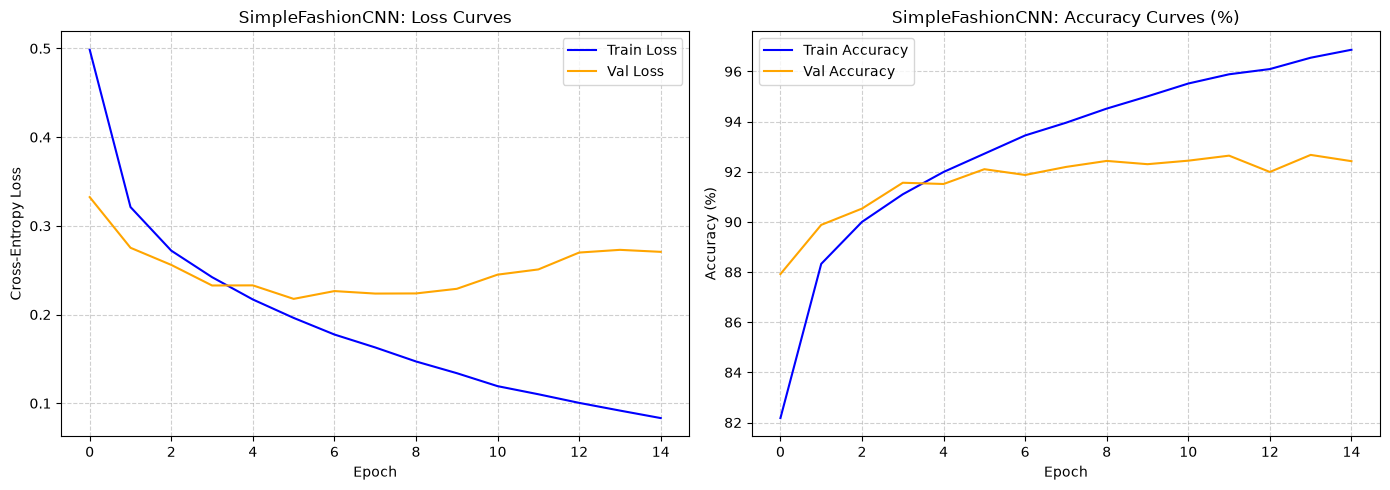

In [16]:
# Extract predictions, targets, and probabilities from baseline test details
probs = test_details_baseline["probabilities"]
preds = test_details_baseline["predictions"]
targets = test_details_baseline["targets"]

# Compute global test accuracy and display summary
test_accuracy = (preds == targets).mean() * 100.0
print(f"Model Name: SimpleFashionCNN")
print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Total Test Samples: {len(targets)}")

# Optional: Plot training and validation loss/accuracy curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_baseline["train_loss"], label="Train Loss", color="blue")
axes[0].plot(history_baseline["val_loss"], label="Val Loss", color="orange")
axes[0].set_title("SimpleFashionCNN: Loss Curves")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.6)

axes[1].plot(history_baseline["train_acc"], label="Train Accuracy", color="blue")
axes[1].plot(history_baseline["val_acc"], label="Val Accuracy", color="orange")
axes[1].set_title("SimpleFashionCNN: Accuracy Curves (%)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)

os.makedirs(f"figures/{MODEL_NAME}", exist_ok=True); plt.savefig(f"figures/{MODEL_NAME}/learning_curves.png", bbox_inches="tight", dpi=300)

plt.tight_layout()
plt.show()

#### Confusion matrix

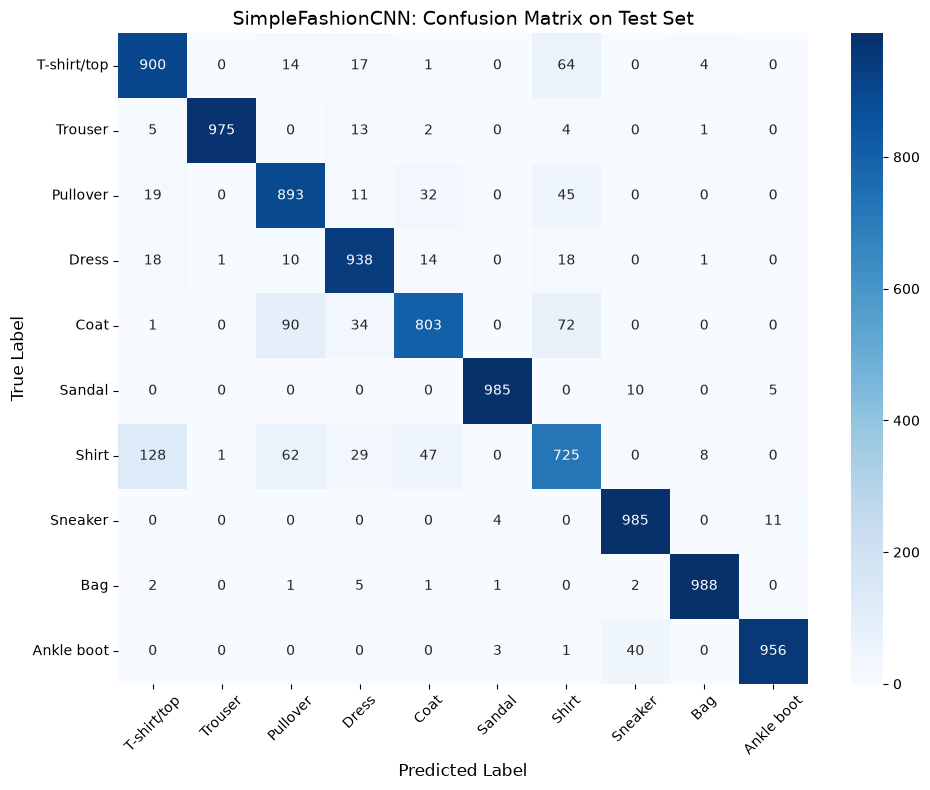

In [17]:
# Compute and display confusion matrix
cm = confusion_matrix(targets, preds)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.title("SimpleFashionCNN: Confusion Matrix on Test Set", fontsize=14)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.xticks(rotation=45)

os.makedirs(f"figures/{MODEL_NAME}", exist_ok=True); plt.savefig(f"figures/{MODEL_NAME}/confusion_matrix.png", bbox_inches="tight", dpi=300)

plt.tight_layout()
plt.show()

#### Examples for which the model is correct with high confidence

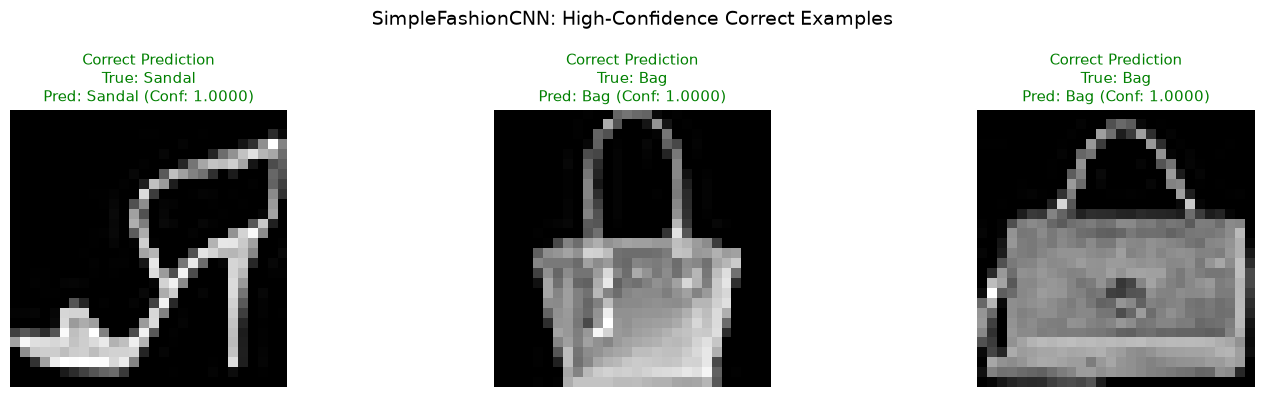

In [18]:
# Calculate maximum softmax probability (confidence) for each test sample
confidences = np.max(probs, axis=1)
is_correct = (preds == targets)

# Helper function to unnormalize images for plotting
def unnormalize(tensor_img):
    img = tensor_img.clone().numpy().squeeze()
    img = (img * 0.5) + 0.5  # Revert normalization [-1, 1] -> [0, 1]
    return np.clip(img, 0, 1)

# Find top-3 correct predictions with highest confidence
correct_indices = np.where(is_correct)[0]
top_correct_idx = correct_indices[np.argsort(-confidences[correct_indices])[:3]]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, idx in enumerate(top_correct_idx):
    img, _ = test_dataset[idx]
    axes[i].imshow(unnormalize(img), cmap="gray")
    axes[i].set_title(
        f"Correct Prediction\nTrue: {class_names[targets[idx]]}\n"
        f"Pred: {class_names[preds[idx]]} (Conf: {confidences[idx]:.4f})",
        color="green", fontsize=11
    )
    axes[i].axis("off")

plt.suptitle("SimpleFashionCNN: High-Confidence Correct Examples", fontsize=14)

os.makedirs(f"figures/{MODEL_NAME}", exist_ok=True); plt.savefig(f"figures/{MODEL_NAME}/high_conf_correct.png", bbox_inches="tight", dpi=300)

plt.tight_layout()
plt.show()

#### Examples for which the model is wrong with high confidence

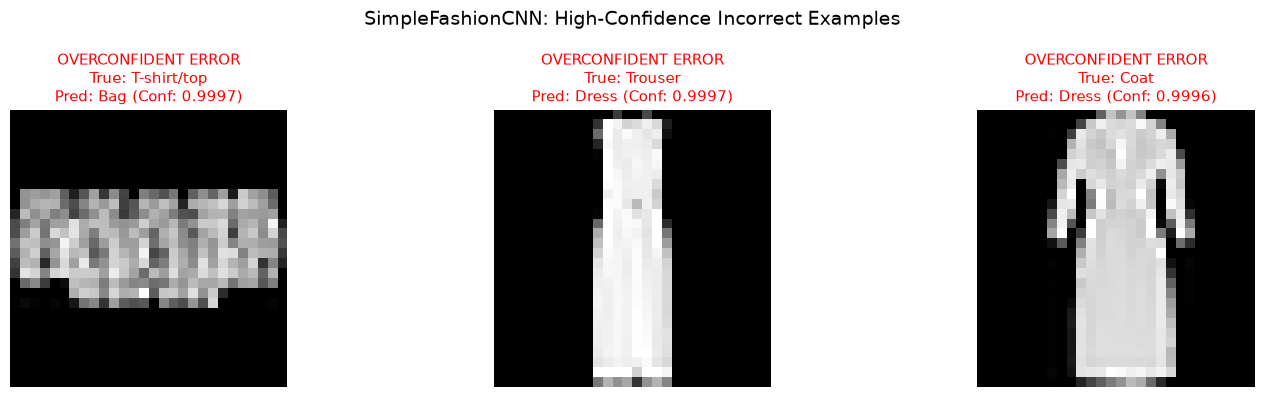

In [19]:
# Find top-3 wrong predictions with highest confidence (Overconfident Errors)
incorrect_indices = np.where(~is_correct)[0]
top_incorrect_idx = incorrect_indices[np.argsort(-confidences[incorrect_indices])[:3]]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, idx in enumerate(top_incorrect_idx):
    img, _ = test_dataset[idx]
    axes[i].imshow(unnormalize(img), cmap="gray")
    axes[i].set_title(
        f"OVERCONFIDENT ERROR\nTrue: {class_names[targets[idx]]}\n"
        f"Pred: {class_names[preds[idx]]} (Conf: {confidences[idx]:.4f})",
        color="red", fontsize=11
    )
    axes[i].axis("off")

plt.suptitle("SimpleFashionCNN: High-Confidence Incorrect Examples", fontsize=14)

os.makedirs(f"figures/{MODEL_NAME}", exist_ok=True); plt.savefig(f"figures/{MODEL_NAME}/high_conf_wrong.png", bbox_inches="tight", dpi=300)

plt.tight_layout()
plt.show()

#### The complete predictive probability vector for several ambiguous examples

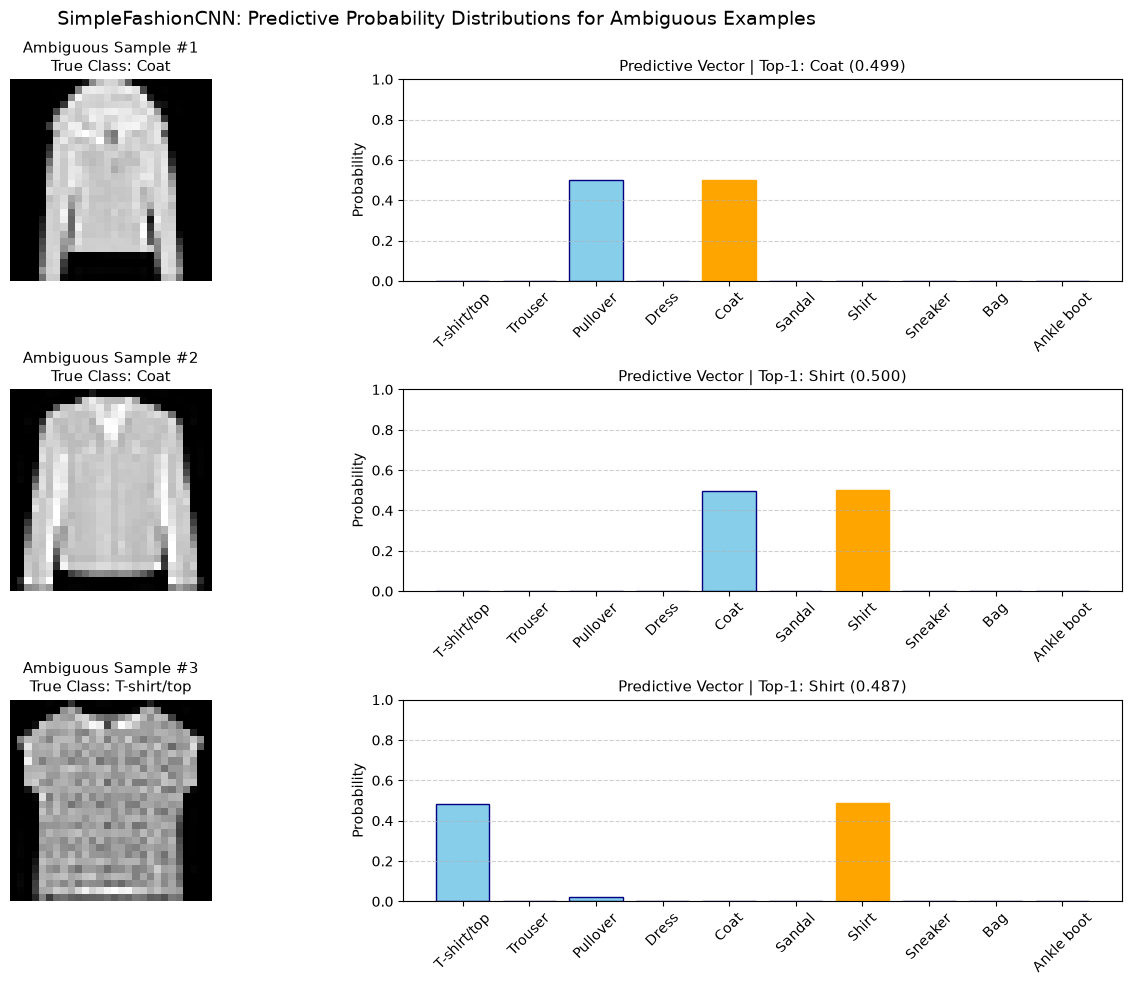

In [20]:
# Measure ambiguity using the margin between top-1 and top-2 softmax probabilities
sorted_probs = np.sort(probs, axis=1)
margins = sorted_probs[:, -1] - sorted_probs[:, -2]  # Smallest margin = highest ambiguity
ambiguous_idx = np.argsort(margins)[:3]

fig, axes = plt.subplots(3, 2, figsize=(14, 10))

for i, idx in enumerate(ambiguous_idx):
    img, _ = test_dataset[idx]

    # Image plot
    axes[i, 0].imshow(unnormalize(img), cmap="gray")
    axes[i, 0].set_title(
        f"Ambiguous Sample #{i+1}\nTrue Class: {class_names[targets[idx]]}",
        fontsize=11
    )
    axes[i, 0].axis("off")

    # Complete probability vector plot
    bars = axes[i, 1].bar(class_names, probs[idx], color="skyblue", edgecolor="navy")
    bars[preds[idx]].set_color("orange")  # Highlight predicted class
    axes[i, 1].set_ylabel("Probability")
    axes[i, 1].set_ylim(0, 1)
    axes[i, 1].tick_params(axis="x", rotation=45)
    axes[i, 1].set_title(
        f"Predictive Vector | Top-1: {class_names[preds[idx]]} ({probs[idx, preds[idx]]:.3f})",
        fontsize=11
    )
    axes[i, 1].grid(axis="y", linestyle="--", alpha=0.6)

plt.suptitle("SimpleFashionCNN: Predictive Probability Distributions for Ambiguous Examples", fontsize=14)

os.makedirs(f"figures/{MODEL_NAME}", exist_ok=True); plt.savefig(f"figures/{MODEL_NAME}/ambiguous_examples.png", bbox_inches="tight", dpi=300)

plt.tight_layout()
plt.show()

## Task 3 (Calibration Evaluation)

### Function to compute ECE and plot the reliabilty diagram

In [21]:
def compute_ece_and_plot_diagram(
    probs: np.ndarray,
    targets: np.ndarray,
    n_bins: int = 10,
    model_name: str = "SimpleFashionCNN",
    save_fig: bool = True,
    save_json: bool = True
) -> Tuple[float, Dict[str, Any]]:
    """
    Computes Expected Calibration Error (ECE) and plots a Reliability Diagram.

    Args:
        probs: Softmax probability matrix of shape (N, num_classes).
        targets: True class labels of shape (N,).
        n_bins: Number of equal-width bins in [0, 1].
        model_name: Name used for output paths and chart title.
        save_fig: If True, saves plot to figures/{model_name}/reliability_diagram.png.
        save_json: If True, saves ECE and bin statistics to checkpoints/{model_name}/calibration_baseline.json.

    Returns:
        Tuple containing (ECE_value, calibration_summary_dict).
    """
    confidences = np.max(probs, axis=1)
    predictions = np.argmax(probs, axis=1)
    accuracies = (predictions == targets)

    bin_boundaries = np.linspace(0, 1, n_bins + 1)

    bin_accs = []
    bin_confs = []
    bin_sizes = []

    ece = 0.0
    total_samples = len(targets)

    for i in range(n_bins):
        bin_lower = bin_boundaries[i]
        bin_upper = bin_boundaries[i + 1]

        # Select samples within current confidence interval bin
        if i == n_bins - 1:
            in_bin = (confidences >= bin_lower) & (confidences <= bin_upper)
        else:
            in_bin = (confidences >= bin_lower) & (confidences < bin_upper)

        bin_size = np.sum(in_bin)
        bin_sizes.append(int(bin_size))

        if bin_size > 0:
            avg_acc = np.mean(accuracies[in_bin])
            avg_conf = np.mean(confidences[in_bin])

            bin_accs.append(float(avg_acc))
            bin_confs.append(float(avg_conf))

            # Accumulate weighted absolute calibration error
            ece += (bin_size / total_samples) * np.abs(avg_acc - avg_conf)
        else:
            bin_accs.append(0.0)
            bin_confs.append(float((bin_lower + bin_upper) / 2.0))

    # Plot Reliability Diagram
    fig, ax = plt.subplots(figsize=(8, 6))

    # Perfect calibration diagonal
    ax.plot([0, 1], [0, 1], "k--", label="Perfect Calibration")

    # Observed accuracy bars
    bin_centers = (bin_boundaries[:-1] + bin_boundaries[1:]) / 2
    width = 1.0 / n_bins

    # Plot bars with gap visual representation
    ax.bar(
        bin_centers, bin_accs, width=width * 0.85, alpha=0.7,
        color="royalblue", edgecolor="navy", label="Observed Accuracy"
    )

    # Highlight calibration gap
    for i in range(n_bins):
        if bin_sizes[i] > 0:
            ax.bar(
                bin_centers[i], np.abs(bin_accs[i] - bin_confs[i]),
                bottom=min(bin_accs[i], bin_confs[i]), width=width * 0.85,
                color="salmon", alpha=0.5,
                label="Calibration Gap" if i == 0 else ""
            )

    ax.set_xlabel("Confidence", fontsize=12)
    ax.set_ylabel("Accuracy", fontsize=12)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_title(f"Reliability Diagram: {model_name} (ECE: {ece * 100:.2f}%)", fontsize=14)
    ax.legend(loc="upper left")
    ax.grid(True, linestyle="--", alpha=0.5)

    # Save figure dynamically
    if save_fig:
        fig_dir = f"figures/{model_name}"
        os.makedirs(fig_dir, exist_ok=True)
        plt.savefig(f"{fig_dir}/reliability_diagram.png", bbox_inches="tight", dpi=300)

    plt.show()

    # Save metrics summary
    metrics_summary = {
        "model_name": model_name,
        "ece": float(ece),
        "overall_accuracy": float(np.mean(accuracies)),
        "bin_accuracies": bin_accs,
        "bin_confidences": bin_confs,
        "bin_sizes": bin_sizes
    }

    if save_json:
        ckpt_dir = f"checkpoints/{model_name}"
        os.makedirs(ckpt_dir, exist_ok=True)
        with open(f"{ckpt_dir}/calibration_baseline.json", "w") as f:
            json.dump(metrics_summary, f, indent=4)

    return float(ece), metrics_summary

### Executing the calculation

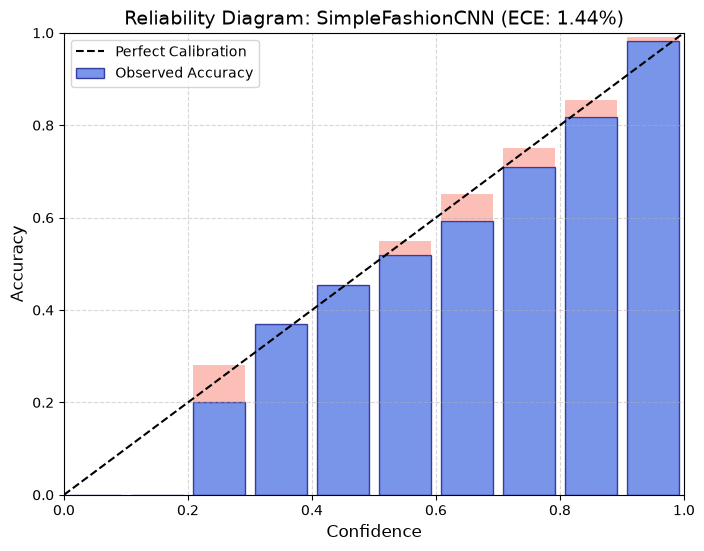


--- Task 3 Calibration Summary ---
Overall Test Accuracy: 91.48%
Expected Calibration Error (ECE): 1.44%


In [22]:
# Task 3: Reliability Diagram and ECE Calculation for Baseline CNN
probs_baseline = test_details_baseline["probabilities"]
targets_baseline = test_details_baseline["targets"]

ece_baseline, calibration_summary_baseline = compute_ece_and_plot_diagram(
    probs=probs_baseline,
    targets=targets_baseline,
    n_bins=10,
    model_name=MODEL_NAME,
    save_fig=True,
    save_json=True
)

print(f"\n--- Task 3 Calibration Summary ---")
print(f"Overall Test Accuracy: {calibration_summary_baseline['overall_accuracy'] * 100:.2f}%")
print(f"Expected Calibration Error (ECE): {ece_baseline * 100:.2f}%")

### Answering the questions

#### 1. Is the model overconfident or underconfident?

Based on the empirical results, the baseline model (**SimpleFashionCNN**) is **systematically overconfident**, although it exhibits a very low overall Expected Calibration Error ($\text{ECE} \approx 1.44\%$).

**Justification from Empirical Data:**
* In almost all populated confidence bins—especially those containing the vast majority of samples—the predicted confidence ($\text{conf}(B_j)$) is strictly higher than the observed accuracy ($\text{acc}(B_j)$):
  * **Bin $[0.9, 1.0]$** (7,914 samples / 79.14% of the test set): Average confidence is **99.01%**, but observed accuracy is **98.16%** ($\text{gap} = 0.85\%$).
  * **Bin $[0.8, 0.9]$** (653 samples): Average confidence is **85.36%**, but observed accuracy is **81.78%** ($\text{gap} = 3.58\%$).
  * **Bin $[0.7, 0.8]$** (487 samples): Average confidence is **75.14%**, but observed accuracy is **71.05%** ($\text{gap} = 4.09\%$).
  * **Bin $[0.6, 0.7]$** (369 samples): Average confidence is **65.20%**, but observed accuracy is **59.35%** ($\text{gap} = 5.85\%$).
* Because $\text{conf}(B_j) > \text{acc}(B_j)$ across all bins with significant sample counts, the model systematically estimates a higher probability of being correct than its actual performance warrants.

#### 2. Can a model have excellent accuracy and poor calibration?

**Yes, absolutely.** Accuracy and calibration measure two fundamentally different aspects of a classifier's predictions:

1. **Classification Accuracy** depends solely on the discrete ranking of outputs ($\operatorname{argmax}_k p(Y=k|x)$). As long as the correct class index receives the highest logit/softmax probability, the prediction is counted as 100% correct, regardless of whether the probability value is 0.11 or 0.9999.
2. **Probability Calibration** evaluates the numerical reliability of the probability score itself ($c(x) = \max_k p(Y=k|x)$). 

**Illustrative Counterexample:**
A neural network could achieve an outstanding **95% accuracy** on a dataset. However, if it outputs a softmax confidence of **99.99%** for every single prediction, its Expected Calibration Error would be approximately $ECE \approx |0.95 - 0.9999| = 4.99\%$. The model would be heavily overconfident and uncalibrated despite its high accuracy.

#### 3. Interpret the reliability diagram.

The Reliability Diagram for **SimpleFashionCNN** provides a bin-by-bin visual analysis of predicted confidence versus observed accuracy:

1. **Sample Distribution Concentration**:
   * Out of 10,000 test samples, **7,914 images (79.14%)** fall into the highest confidence bin $[0.9, 1.0]$. This indicates that the network makes most of its predictions with extreme certainty.
2. **Alignment with Perfect Calibration Line**:
   * The observed accuracy bars (blue) closely follow the black dashed diagonal line ($y = x$). This tight alignment accounts for the low overall $\text{ECE}$ of **1.44%**.
3. **Overconfidence Gap Visualization**:
   * For confidence bins between $0.5$ and $1.0$, the blue bars consistently end below the diagonal line, leaving a visible pink region (*Calibration Gap*). This confirms mild, systematic overconfidence in high-certainty predictions.
4. **Empty Low-Confidence Bins**:
   * The first two bins ($[0.0, 0.1]$ and $[0.1, 0.2]$) contain zero samples. In a 10-class problem, the maximum softmax probability is mathematically bounded below by $1/10 = 0.1$, and a trained network rarely outputs a maximum confidence lower than $0.2$.

#### 4. What is the link between ECE and the reliability diagram?

There is a direct geometric and mathematical link between the **Reliability Diagram** and the **Expected Calibration Error (ECE)**:

* **The Reliability Diagram is the visual representation of bin-wise calibration gaps:**
  For each bin $B_j$, the diagram plots the observed accuracy $\text{acc}(B_j)$ against predicted confidence $\text{conf}(B_j)$, highlighting the absolute error gap $| \text{acc}(B_j) - \text{conf}(B_j) |$ (the pink regions).
* **ECE is the single scalar metric derived directly from the diagram:**
  ECE computes the weighted average of the heights of all the pink calibration gaps across all bins, where the weights are proportional to the number of samples $|B_j|$ in each bin relative to the total dataset size $N$:

  $$\text{ECE} = \sum_{j=1}^{M} \frac{|B_j|}{N} \left| \text{acc}(B_j) - \text{conf}(B_j) \right|$$

In summary, the **Reliability Diagram** provides the local, bin-by-bin diagnostic view, while **ECE** summarizes the total area of those calibration gaps into a global metric.

## Task 4 (Calibrate the model: Temperature scaling)

### Temperature Scaling Module Definition

In [23]:
class ModelWithTemperature(nn.Module):
    """
    A decorator wrapper around a trained neural network that learns a single
    scalar parameter T (Temperature) on the calibration/validation dataset
    to calibrate softmax probabilities via logit scaling.
    """
    def __init__(self, model: nn.Module):
        super(ModelWithTemperature, self).__init__()
        self.model = model
        # Initialize temperature parameter T = 1.0
        self.temperature = nn.Parameter(torch.ones(1) * 1.0)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        logits = self.model(x)
        return self.temperature_scale(logits)

    def temperature_scale(self, logits: torch.Tensor) -> torch.Tensor:
        """
        Scales logits by dividing by temperature T.
        """
        # Expand temperature to match logit shape
        temperature = self.temperature.unsqueeze(1).expand(logits.size(0), logits.size(1))
        return logits / temperature

    def set_temperature(self, calib_loader: DataLoader, device: torch.device) -> float:
        """
        Finds optimal temperature T by minimizing Negative Log-Likelihood (NLL)
        strictly on the calibration/validation dataset using L-BFGS.
        """
        self.model.eval()
        nll_criterion = nn.CrossEntropyLoss().to(device)

        # 1. Collect all logits and targets from calibration set
        logits_list = []
        labels_list = []

        with torch.no_grad():
            for images, targets in calib_loader:
                images = images.to(device)
                logits = self.model(images)
                logits_list.append(logits)
                labels_list.append(targets.to(device))

        logits = torch.cat(logits_list, dim=0)
        labels = torch.cat(labels_list, dim=0)

        # 2. Evaluate NLL before temperature scaling
        before_temperature_nll = nll_criterion(logits, labels).item()
        print(f"Calibration Set NLL before Temperature Scaling: {before_temperature_nll:.4f}")

        # 3. Optimize scalar temperature T using L-BFGS
        optimizer = optim.LBFGS([self.temperature], lr=0.01, max_iter=50)

        def eval_loss():
            optimizer.zero_grad()
            loss = nll_criterion(self.temperature_scale(logits), labels)
            loss.backward()
            return loss

        optimizer.step(eval_loss)

        # 4. Evaluate NLL after temperature scaling
        after_temperature_nll = nll_criterion(self.temperature_scale(logits), labels).item()
        optimal_t = self.temperature.item()

        print(f"Optimal Temperature T learned on Calibration Set: {optimal_t:.4f}")
        print(f"Calibration Set NLL after Temperature Scaling: {after_temperature_nll:.4f}")

        return optimal_t

### Learn Temperature T on Calibration Set

In [24]:
# Instantiate temperature wrapper around baseline CNN
calibrated_model = ModelWithTemperature(model_baseline).to(device)

# Learn optimal scalar T strictly on the calibration dataset
optimal_T = calibrated_model.set_temperature(calib_loader=calib_loader, device=device)

# Save learned temperature parameter to checkpoints
ckpt_dir = f"checkpoints/{MODEL_NAME}"
os.makedirs(ckpt_dir, exist_ok=True)
with open(f"{ckpt_dir}/temperature.json", "w") as f:
    json.dump({"model_name": MODEL_NAME, "optimal_temperature": optimal_T}, f, indent=4)

print(f"\nSaved optimal temperature T = {optimal_T:.4f} to '{ckpt_dir}/temperature.json'")

Calibration Set NLL before Temperature Scaling: 0.2177
Optimal Temperature T learned on Calibration Set: 1.0536
Calibration Set NLL after Temperature Scaling: 0.2161

Saved optimal temperature T = 1.0536 to 'checkpoints/SimpleFashionCNN/temperature.json'


### Evaluate Metrics Before and After Calibration on Test Set

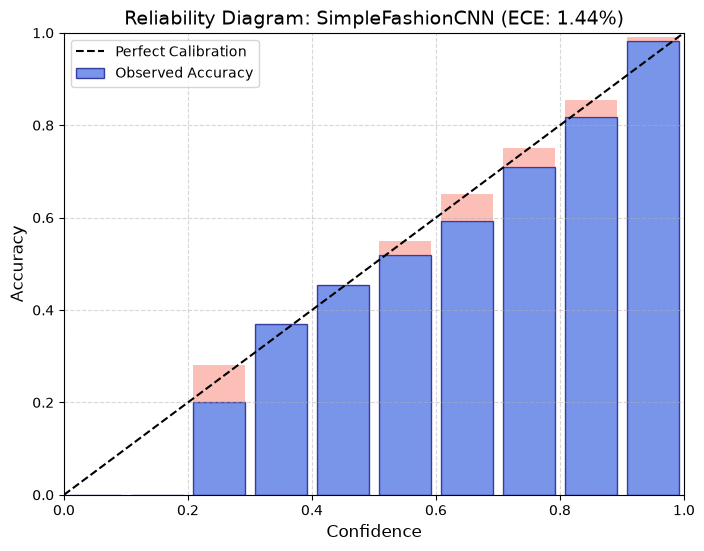

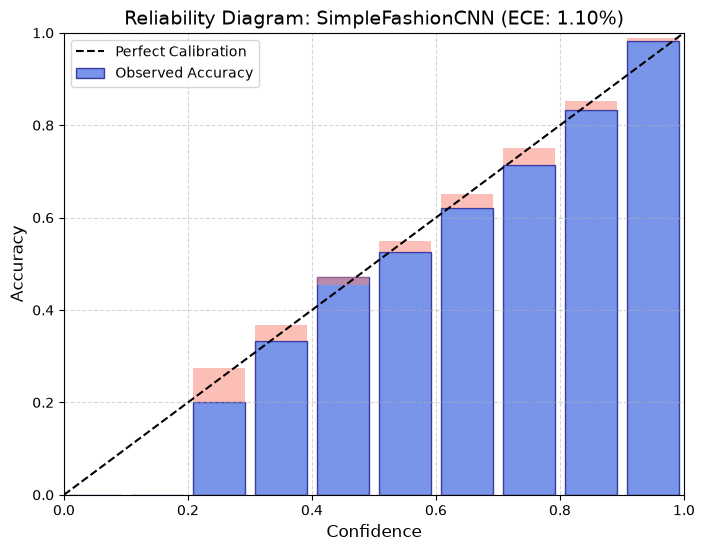


      TEST SET METRICS: BEFORE vs AFTER CALIBRATION    
Metric             | Before (T = 1.0) | After (T = 1.0536)
-------------------|------------------|------------------
Accuracy (%)       | 91.48%           | 91.48%
NLL (Log Loss)     | 0.2364           | 0.2341
ECE (%)            | 1.44%          | 1.10%


In [25]:
# Function to extract test logits, compute NLL, Probs, Accuracy, and ECE
def evaluate_model_calibration(logits_raw: torch.Tensor, targets: torch.Tensor, temp: float = 1.0):
    logits_scaled = logits_raw / temp
    probs = F.softmax(logits_scaled, dim=1).numpy()
    targets_np = targets.numpy()

    # Compute Cross-Entropy Loss (NLL)
    nll_loss = nn.CrossEntropyLoss()(logits_scaled, targets).item()

    # Compute Accuracy
    preds = np.argmax(probs, axis=1)
    acc = (preds == targets_np).mean() * 100.0

    # Compute ECE
    ece, _ = compute_ece_and_plot_diagram(
        probs=probs, targets=targets_np, n_bins=10,
        model_name=MODEL_NAME, save_fig=False, save_json=False
    )

    return nll_loss, acc, ece, probs

# Extract test set logits and targets
test_logits_tensor = torch.tensor(test_details_baseline["logits"])
test_targets_tensor = torch.tensor(test_details_baseline["targets"])

# 1. Uncalibrated (T = 1.0)
nll_before, acc_before, ece_before, probs_uncalibrated = evaluate_model_calibration(
    test_logits_tensor, test_targets_tensor, temp=1.0
)

# 2. Calibrated (T = optimal_T)
nll_after, acc_after, ece_after, probs_calibrated = evaluate_model_calibration(
    test_logits_tensor, test_targets_tensor, temp=optimal_T
)

# Print Comparison Table
print(f"\n=======================================================")
print(f"      TEST SET METRICS: BEFORE vs AFTER CALIBRATION    ")
print(f"=======================================================")
print(f"Metric             | Before (T = 1.0) | After (T = {optimal_T:.4f})")
print(f"-------------------|------------------|------------------")
print(f"Accuracy (%)       | {acc_before:.2f}%           | {acc_after:.2f}%")
print(f"NLL (Log Loss)     | {nll_before:.4f}           | {nll_after:.4f}")
print(f"ECE (%)            | {ece_before * 100:.2f}%          | {ece_after * 100:.2f}%")
print(f"=======================================================")

# Save calibrated test details in PKL for downstream tasks (Conformal / Utility)
calibrated_test_details = {
    "logits_unscaled": test_details_baseline["logits"],
    "logits_scaled": (test_logits_tensor / optimal_T).numpy(),
    "probabilities": probs_calibrated,
    "predictions": np.argmax(probs_calibrated, axis=1),
    "targets": test_details_baseline["targets"],
    "temperature": optimal_T
}

with open(f"{ckpt_dir}/test_details_calibrated.pkl", "wb") as f:
    pickle.dump(calibrated_test_details, f)

# Save metric comparison JSON
comparison_summary = {
    "model_name": MODEL_NAME,
    "optimal_temperature": optimal_T,
    "accuracy_before": acc_before,
    "accuracy_after": acc_after,
    "nll_before": nll_before,
    "nll_after": nll_after,
    "ece_before": ece_before,
    "ece_after": ece_after
}

with open(f"{ckpt_dir}/calibration_comparison.json", "w") as f:
    json.dump(comparison_summary, f, indent=4)

### Side-by-Side Reliability Diagram Comparison

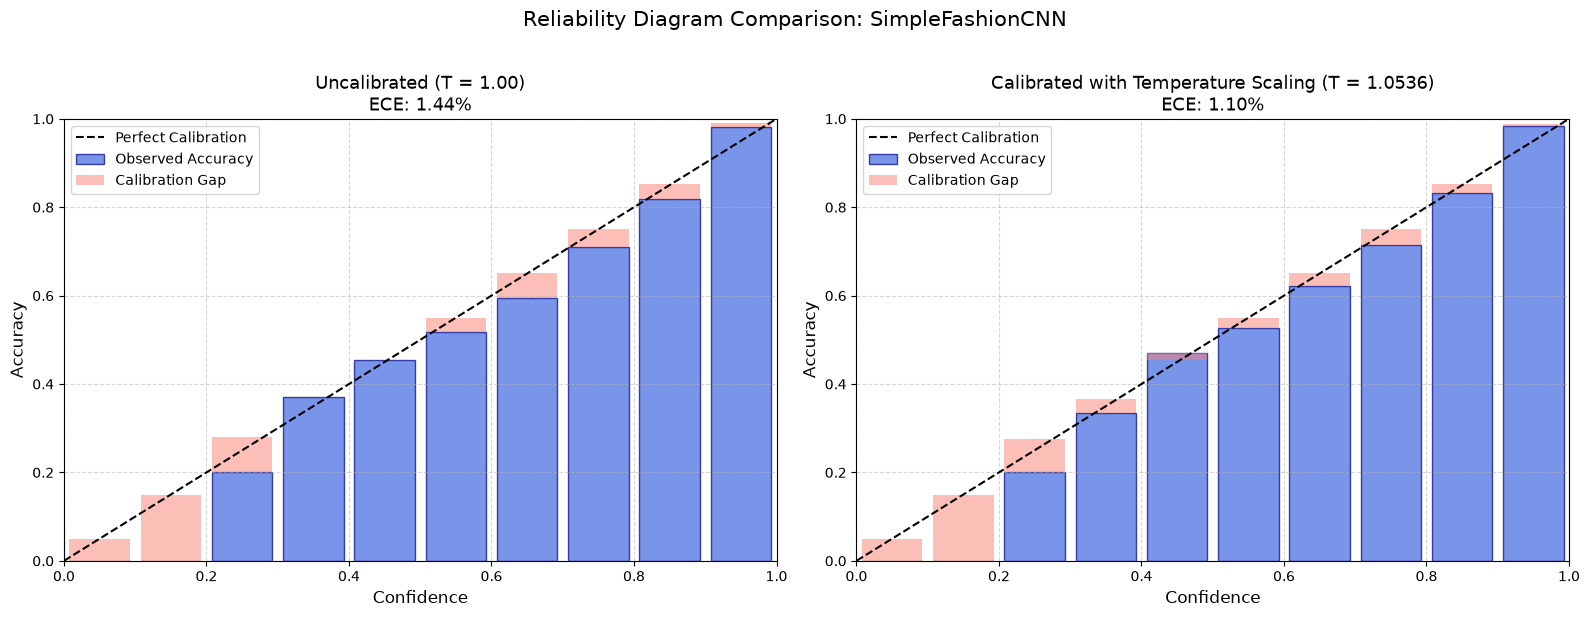

In [26]:
def plot_side_by_side_reliability_diagrams(
    probs_before: np.ndarray,
    probs_after: np.ndarray,
    targets: np.ndarray,
    optimal_t: float,
    model_name: str = "SimpleFashionCNN",
    n_bins: int = 10
):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    bin_boundaries = np.linspace(0, 1, n_bins + 1)
    bin_centers = (bin_boundaries[:-1] + bin_boundaries[1:]) / 2
    width = 1.0 / n_bins
    total_samples = len(targets)

    for ax_idx, (probs, title, temp_val) in enumerate([
        (probs_before, f"Uncalibrated (T = 1.00)", 1.0),
        (probs_after, f"Calibrated with Temperature Scaling (T = {optimal_t:.4f})", optimal_t)
    ]):
        ax = axes[ax_idx]
        confidences = np.max(probs, axis=1)
        predictions = np.argmax(probs, axis=1)
        accuracies = (predictions == targets)

        bin_accs, bin_confs, ece = [], [], 0.0

        for i in range(n_bins):
            bin_lower, bin_upper = bin_boundaries[i], bin_boundaries[i + 1]
            if i == n_bins - 1:
                in_bin = (confidences >= bin_lower) & (confidences <= bin_upper)
            else:
                in_bin = (confidences >= bin_lower) & (confidences < bin_upper)

            bin_size = np.sum(in_bin)
            if bin_size > 0:
                avg_acc = np.mean(accuracies[in_bin])
                avg_conf = np.mean(confidences[in_bin])
                bin_accs.append(avg_acc)
                bin_confs.append(avg_conf)
                ece += (bin_size / total_samples) * np.abs(avg_acc - avg_conf)
            else:
                bin_accs.append(0.0)
                bin_confs.append((bin_lower + bin_upper) / 2.0)

        # Plot perfect calibration diagonal
        ax.plot([0, 1], [0, 1], "k--", label="Perfect Calibration")

        # Plot observed accuracy
        ax.bar(
            bin_centers, bin_accs, width=width * 0.85, alpha=0.7,
            color="royalblue", edgecolor="navy", label="Observed Accuracy"
        )

        # Plot calibration gaps
        for i in range(n_bins):
            ax.bar(
                bin_centers[i], np.abs(bin_accs[i] - bin_confs[i]),
                bottom=min(bin_accs[i], bin_confs[i]), width=width * 0.85,
                color="salmon", alpha=0.5,
                label="Calibration Gap" if i == 0 else ""
            )

        ax.set_xlabel("Confidence", fontsize=12)
        ax.set_ylabel("Accuracy", fontsize=12)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_title(f"{title}\nECE: {ece * 100:.2f}%", fontsize=13)
        ax.legend(loc="upper left")
        ax.grid(True, linestyle="--", alpha=0.5)

    plt.suptitle(f"Reliability Diagram Comparison: {model_name}", fontsize=15, y=1.02)
    plt.tight_layout()

    # Save comparison figure dynamically
    fig_dir = f"figures/{model_name}"
    os.makedirs(fig_dir, exist_ok=True)
    plt.savefig(f"{fig_dir}/reliability_diagram_before_after_ts.png", bbox_inches="tight", dpi=300)
    plt.show()

# Run side-by-side plot
plot_side_by_side_reliability_diagrams(
    probs_before=probs_uncalibrated,
    probs_after=probs_calibrated,
    targets=test_details_baseline["targets"],
    optimal_t=optimal_T,
    model_name=MODEL_NAME
)

### Aswering the questions

#### Summary Table on Test Set

| Metric | Uncalibrated ($T = 1.0000$) | Calibrated ($T = 1.0536$) | Absolute Change ($\Delta$) | Impact / Result |
| :--- | :---: | :---: | :---: | :--- |
| **Accuracy (%)** | **91.48%** | **91.48%** | **0.00%** | **Unchanged** (Preserves predictions) |
| **NLL (Log Loss)** | **0.2364** | **0.2341** | **-0.0023** | **Improved** (Better probabilistic quality) |
| **ECE (%)** | **1.44%** | **1.10%** | **-0.34%** | **Improved** (Lower calibration error) |

#### Detailed Breakdown of Metrics

1. **Accuracy (91.48% $\rightarrow$ 91.48%)**:
   * The classification accuracy remains **strictly identical** before and after applying Temperature Scaling.

2. **Negative Log-Likelihood (NLL: 0.2364 $\rightarrow$ 0.2341)**:
   * The Negative Log-Likelihood (cross-entropy loss) on the test set decreased from **0.2364** to **0.2341**.
   * Because $T = 1.0536$ was learned by directly minimizing NLL on the validation/calibration set, the resulting scaled probabilities assign higher, better-calibrated likelihoods to the true target classes.

3. **Expected Calibration Error (ECE: 1.44% $\rightarrow$ 1.10%)**:
   * The global Expected Calibration Error decreased from **1.44%** to **1.10%**, achieving a **~23.6% relative reduction** in probability miscalibration.
   * By scaling logits with $T = 1.0536 > 1$, the model slightly reduces its overconfident peak probabilities, aligning them closer to empirical accuracy.

4. **Reliability Diagram Interpretation**:
   * **Before Scaling ($T = 1.0000$, $\text{ECE} = 1.44\%$)**: The uncalibrated reliability diagram exhibited visible pink calibration gaps across high-confidence bins ($[0.7, 1.0]$), confirming that predicted softmax probabilities were slightly overconfident relative to observed accuracy.
   * **After Scaling ($T = 1.0536$, $\text{ECE} = 1.10\%$)**: The temperature division softens the overconfident logit outputs. This shifts predicted confidences slightly leftward toward their true observed accuracies, shrinking the pink gap areas and aligning the blue bars even tighter with the diagonal perfect calibration line.

#### Why Classification Accuracy Remains Unchanged?

##### Mathematical Proof & Intuition

The classification decision rule for a input image $x$ selects the class index $k$ that maximizes the output logit $z_k(x)$ (or equivalently, the softmax probability $p(Y=k|x)$):

$$\hat{y}(x) = \arg\max_{k \in \{1, \dots, K\}} p(Y=k|x) = \arg\max_{k \in \{1, \dots, K\}} \left( \frac{\exp(z_k(x))}{\sum_{j=1}^{K} \exp(z_j(x))} \right) = \arg\max_{k \in \{1, \dots, K\}} z_k(x)$$

When Temperature Scaling is applied, every raw logit $z_k(x)$ is divided by the scalar temperature parameter $T > 0$:

$$p_T(Y=k|x) = \frac{\exp\left(\frac{z_k(x)}{T}\right)}{\sum_{j=1}^{K} \exp\left(\frac{z_j(x)}{T}\right)}$$

The new predicted class under temperature scaling is:

$$\hat{y}_T(x) = \arg\max_{k \in \{1, \dots, K\}} p_T(Y=k|x) = \arg\max_{k \in \{1, \dots, K\}} \left( \frac{z_k(x)}{T} \right)$$

Because $T > 0$ is a **strictly positive constant**, dividing all elements of a vector by $T$ is a **strictly monotonic transformation**. Monotonic transformations preserve the relative order ranking of all elements in the logit vector:

$$\forall a, b \in \{1, \dots, K\}: \quad z_a(x) > z_b(x) \iff \frac{z_a(x)}{T} > \frac{z_b(x)}{T} \quad (\text{for } T > 0)$$

Therefore:

$$\arg\max_{k \in \{1, \dots, K\}} \left( \frac{z_k(x)}{T} \right) = \arg\max_{k \in \{1, \dots, K\}} z_k(x) \implies \hat{y}_T(x) = \hat{y}(x)$$

##### Conclusion
Temperature Scaling rescales and smooths the confidence magnitudes $c(x) = \max_k p_T(Y=k|x)$, but **never changes the index of the predicted class $\hat{y}(x)$**. Consequently, the total number of correct classifications stays exactly the same, leaving **accuracy strictly invariant**.

## Task 5 (Conformal Prediction)

### Conformal Prediction Implementation

In [29]:
def compute_conformal_quantile(
    calib_probs: np.ndarray,
    calib_targets: np.ndarray,
    alpha: float
) -> float:
    """
    Computes the empirical quantile q_{1-alpha} of non-conformity scores
    s(x, Y) = 1 - p(Y|x) on the calibration dataset.
    """
    n = len(calib_targets)
    # Extract predicted probability assigned to true target class
    true_class_probs = calib_probs[np.arange(n), calib_targets]

    # Non-conformity scores s_i = 1 - p(Y_i | x_i)
    non_conformity_scores = 1.0 - true_class_probs

    # Finite-sample quantile computation index: ceil((1 - alpha) * (n + 1)) / n
    quantile_val = np.ceil((1.0 - alpha) * (n + 1)) / n
    quantile_val = min(1.0, max(0.0, quantile_val))  # Bound in [0, 1]

    q_hat = np.quantile(non_conformity_scores, quantile_val, method="higher")
    return float(q_hat)


def construct_conformal_prediction_sets(
    test_probs: np.ndarray,
    q_hat: float
) -> List[List[int]]:
    """
    Constructs prediction set Gamma(x) = {k : 1 - p(k|x) <= q_hat} for each test sample.
    """
    prediction_sets = []
    threshold = 1.0 - q_hat

    for i in range(len(test_probs)):
        # Classes meeting probability threshold
        included_classes = np.where(test_probs[i] >= threshold)[0].tolist()
        prediction_sets.append(included_classes)

    return prediction_sets


def evaluate_conformal_prediction(
    prediction_sets: List[List[int]],
    test_targets: np.ndarray
) -> Tuple[float, float]:
    """
    Computes empirical coverage and average prediction set size.
    """
    n = len(test_targets)
    coverage_hits = sum(
        1 for i in range(n) if test_targets[i] in prediction_sets[i]
    )
    empirical_coverage = (coverage_hits / n) * 100.0

    set_sizes = [len(s) for s in prediction_sets]
    avg_set_size = float(np.mean(set_sizes))

    return empirical_coverage, avg_set_size

### Measure Coverage and Average Set Size for Alpha = 0.10 and 0.05

In [30]:
# 1. Get calibrated probabilities on calibration set (calib_loader)
calib_logits_list = []
calib_targets_list = []

model_baseline.eval()
with torch.no_grad():
    for images, targets in calib_loader:
        images = images.to(device)
        logits = model_baseline(images)
        calib_logits_list.append(logits.cpu())
        calib_targets_list.append(targets)

calib_logits_tensor = torch.cat(calib_logits_list, dim=0)
calib_targets_np = torch.cat(calib_targets_list, dim=0).numpy()

# Apply optimal temperature scaling T from Task 4
calib_probs_calibrated = F.softmax(calib_logits_tensor / optimal_T, dim=1).numpy()

# Test set calibrated probabilities from Task 4
test_probs_calibrated = calibrated_test_details["probabilities"]
test_targets_np = calibrated_test_details["targets"]

# 2. Evaluate Conformal Prediction for alpha = 0.10 (90% Target Coverage)
q_90 = compute_conformal_quantile(calib_probs_calibrated, calib_targets_np, alpha=0.10)
sets_90 = construct_conformal_prediction_sets(test_probs_calibrated, q_hat=q_90)
cov_90, avg_size_90 = evaluate_conformal_prediction(sets_90, test_targets_np)

# 3. Evaluate Conformal Prediction for alpha = 0.05 (95% Target Coverage)
q_95 = compute_conformal_quantile(calib_probs_calibrated, calib_targets_np, alpha=0.05)
sets_95 = construct_conformal_prediction_sets(test_probs_calibrated, q_hat=q_95)
cov_95, avg_size_95 = evaluate_conformal_prediction(sets_95, test_targets_np)

# Display Summary Table
print("=======================================================================")
print("             CONFORMAL PREDICTION EVALUATION ON TEST SET               ")
print("=======================================================================")
print("Significance Level (alpha) | Target Coverage | Empirical Coverage | Avg Set Size | Quantile (q_hat)")
print("---------------------------|-----------------|--------------------|--------------|----------------")
print(f"alpha = 0.10              | 90.00%          | {cov_90:.2f}%            | {avg_size_90:.2f}         | {q_90:.4f}")
print(f"alpha = 0.05              | 95.00%          | {cov_95:.2f}%            | {avg_size_95:.2f}         | {q_95:.4f}")
print("=======================================================================")

# Save results to JSON
ckpt_dir = f"checkpoints/{MODEL_NAME}"
os.makedirs(ckpt_dir, exist_ok=True)

conformal_results = {
    "model_name": MODEL_NAME,
    "alpha_0.10": {
        "target_coverage": 90.0,
        "empirical_coverage": cov_90,
        "average_set_size": avg_size_90,
        "quantile_q_hat": q_90
    },
    "alpha_0.05": {
        "target_coverage": 95.0,
        "empirical_coverage": cov_95,
        "average_set_size": avg_size_95,
        "quantile_q_hat": q_95
    }
}

with open(f"{ckpt_dir}/conformal_results.json", "w") as f:
    json.dump(conformal_results, f, indent=4)

# Save prediction sets in PKL
conformal_test_details = {
    "prediction_sets_90": sets_90,
    "prediction_sets_95": sets_95,
    "quantile_90": q_90,
    "quantile_95": q_95
}

with open(f"{ckpt_dir}/test_details_conformal.pkl", "wb") as f:
    pickle.dump(conformal_test_details, f)

             CONFORMAL PREDICTION EVALUATION ON TEST SET               
Significance Level (alpha) | Target Coverage | Empirical Coverage | Avg Set Size | Quantile (q_hat)
---------------------------|-----------------|--------------------|--------------|----------------
alpha = 0.10              | 90.00%          | 89.28%            | 0.95         | 0.4398
alpha = 0.05              | 95.00%          | 94.29%            | 1.08         | 0.7125


### Visualize Singleton and Multi-label Prediction Sets

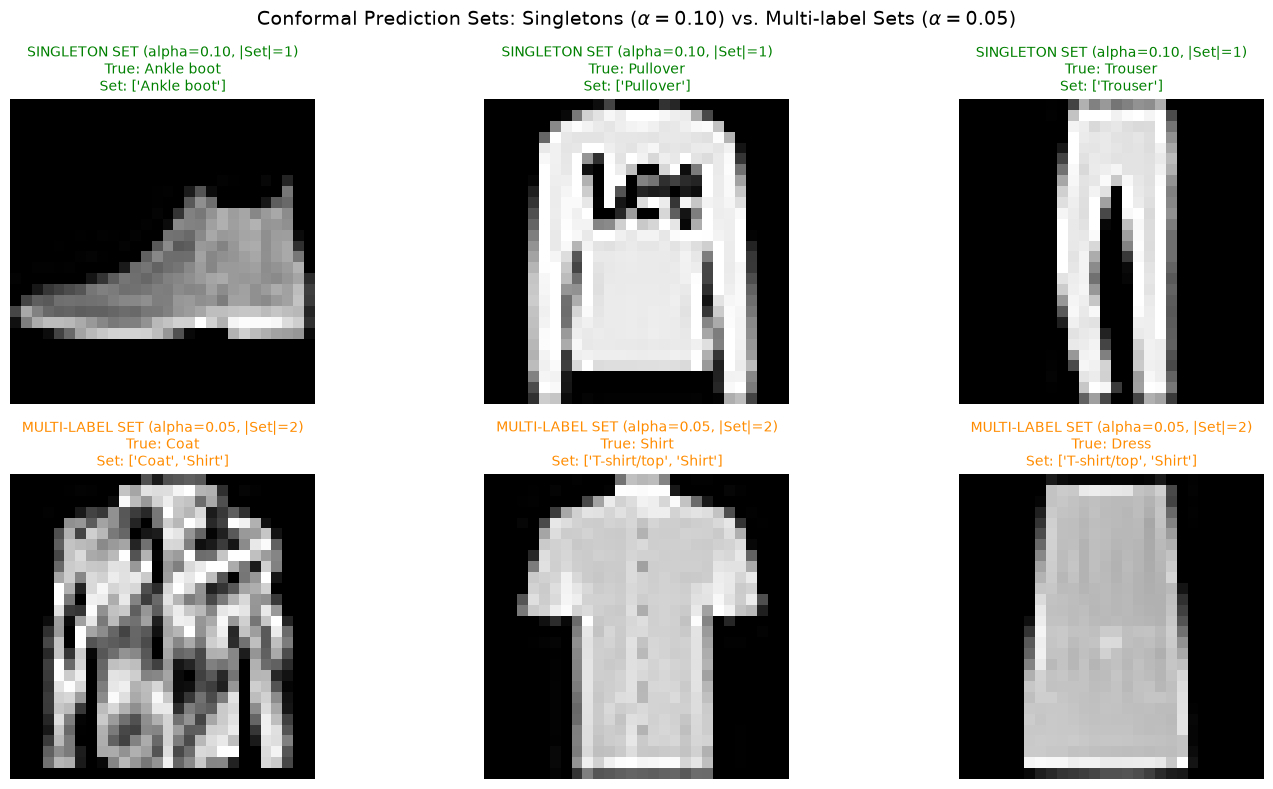

In [32]:
# Set size arrays
set_sizes_90 = np.array([len(s) for s in sets_90])
set_sizes_95 = np.array([len(s) for s in sets_95])

# Find singleton set indices from alpha = 0.10 (|Gamma| = 1)
singleton_indices = np.where(set_sizes_90 == 1)[0][:3]

# Find multi-label set indices from alpha = 0.05 (|Gamma| >= 2)
multilabel_indices = np.where(set_sizes_95 >= 2)[0][:3]

def unnormalize(tensor_img):
    img = tensor_img.clone().numpy().squeeze()
    img = (img * 0.5) + 0.5
    return np.clip(img, 0, 1)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Row 1: Singletons from alpha = 0.10
for i, idx in enumerate(singleton_indices):
    img, _ = test_dataset[idx]
    true_label = class_names[test_targets_np[idx]]
    pred_set_labels = [class_names[c] for c in sets_90[idx]]

    axes[0, i].imshow(unnormalize(img), cmap="gray")
    axes[0, i].set_title(
        f"SINGLETON SET (alpha=0.10, |Set|=1)\nTrue: {true_label}\nSet: {pred_set_labels}",
        color="green", fontsize=10
    )
    axes[0, i].axis("off")

# Row 2: Multi-label Sets from alpha = 0.05
for i, idx in enumerate(multilabel_indices):
    img, _ = test_dataset[idx]
    true_label = class_names[test_targets_np[idx]]
    pred_set_labels = [class_names[c] for c in sets_95[idx]]

    axes[1, i].imshow(unnormalize(img), cmap="gray")
    axes[1, i].set_title(
        f"MULTI-LABEL SET (alpha=0.05, |Set|={len(sets_95[idx])})\nTrue: {true_label}\nSet: {pred_set_labels}",
        color="darkorange", fontsize=10
    )
    axes[1, i].axis("off")

plt.suptitle(r"Conformal Prediction Sets: Singletons ($\alpha=0.10$) vs. Multi-label Sets ($\alpha=0.05$)", fontsize=14)
plt.tight_layout()

# Save figure dynamically
fig_dir = f"figures/{MODEL_NAME}"
os.makedirs(fig_dir, exist_ok=True)
plt.savefig(f"{fig_dir}/conformal_prediction_examples.png", bbox_inches="tight", dpi=300)
plt.show()

### Answering the questions

#### Summary Table on Test Set

| Significance Level ($\alpha$) | Target Coverage | Empirical Coverage | Average Set Size | Quantile Threshold ($q_{\hat{}}$) | Probability Inclusion Threshold ($1 - q_{\hat{}}$) |
| :---: | :---: | :---: | :---: | :---: | :---: |
| **$\alpha = 0.10$** | **90.00%** | **89.28%** | **0.95** | **0.4398** | **0.5602 (56.02%)** |
| **$\alpha = 0.05$** | **95.00%** | **94.29%** | **1.08** | **0.7125** | **0.2875 (28.75%)** |

#### Key Findings and Interpretations

1. **Coverage Guarantee Validity**:
   * The empirical coverages obtained on the isolated test set (**89.28%** for $\alpha = 0.10$ and **94.29%** for $\alpha = 0.05$) closely match the theoretical targets ($90\%$ and $95\%$), validating the distribution-free statistical guarantee of Split Conformal Prediction.

2. **Explanation of Average Set Size $< 1.0$ for $\alpha = 0.10$**:
   * For $\alpha = 0.10$, the empirical non-conformity quantile is $q_{0.90} = 0.4398$, requiring a class to have a softmax probability $p(k|x) \ge 1 - 0.4398 = \mathbf{0.5602}$ ($56.02\%$) to be included in $\Gamma(x)$.
   * For ambiguous images where the model's top predicted probability is below $56.02\%$, **no class meets the threshold**, resulting in an **empty prediction set** ($\Gamma(x) = \emptyset$, size 0). These empty sets reduce the average set size across the test set to $0.95$.
   * Furthermore, because $56.02\% > 50\%$, it is mathematically impossible for any image to contain more than 1 class in its prediction set for $\alpha = 0.10$.

3. **Coverage vs. Set Size Trade-off**:
   * Increasing the statistical confidence guarantee from $90\%$ to $95\%$ ($\alpha = 0.10 \to 0.05$) forces the non-conformity quantile to increase ($q_{\hat{}} = 0.4398 \to 0.7125$).
   * This lowers the probability inclusion threshold from $56.02\%$ down to $28.75\%$, allowing the model to include multiple candidate classes ($\ge 2$) for ambiguous images, increasing the average set size from **0.95 to 1.08**.

## Task 6 (Deep Ensemble)

### Deep Ensemble Definition & Multi-Seed Training (M = 5)

In [34]:
# Set seed for reproducibility
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# Diversity Method 1: Train M=5 independent models with different random initializations & data shuffles
def train_ensemble_member(seed: int, epochs: int = 5) -> nn.Module:
    """
    Trains an individual SimpleFashionCNN model with a specific random seed.
    """
    set_seed(seed)
    # Re-instantiate model architecture
    model = SimpleFashionCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    # Data loader with seed-specific shuffle
    g = torch.Generator()
    g.manual_seed(seed)
    train_loader_seeded = DataLoader(train_dataset, batch_size=64, shuffle=True, generator=g)

    model.train()
    for epoch in range(epochs):
        for images, targets in train_loader_seeded:
            images, targets = images.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

    return model

print("Training M = 5 Deep Ensemble models with distinct random seeds...")
ensemble_seeds = [42, 101, 2024, 777, 999]
ensemble_models = []

for idx, seed in enumerate(ensemble_seeds):
    print(f"Training Ensemble Member {idx + 1}/5 (Seed: {seed})...")
    m_model = train_ensemble_member(seed=seed, epochs=10)
    m_model.eval()
    ensemble_models.append(m_model)

print("\nAll 5 ensemble models trained successfully!")

Training M = 5 Deep Ensemble models with distinct random seeds...
Training Ensemble Member 1/5 (Seed: 42)...
Training Ensemble Member 2/5 (Seed: 101)...
Training Ensemble Member 3/5 (Seed: 2024)...
Training Ensemble Member 4/5 (Seed: 777)...
Training Ensemble Member 5/5 (Seed: 999)...

All 5 ensemble models trained successfully!


### Uncertainty Quantification (Total Entropy, Aleatoric, Epistemic Disagreement)

In [35]:
def compute_ensemble_predictions_and_uncertainty(
    models: List[nn.Module],
    data_loader: DataLoader,
    device: torch.device
) -> Dict[str, np.ndarray]:
    """
    Computes ensemble predictive distribution, individual predictions,
    Total Entropy, Aleatoric Uncertainty, and Epistemic Uncertainty (Disagreement).
    """
    all_individual_probs = [] # Shape: (M, N, K)

    # 1. Collect softmax probabilities from all M models
    for m_idx, model in enumerate(models):
        model.eval()
        model_probs = []
        with torch.no_grad():
            for images, _ in data_loader:
                images = images.to(device)
                logits = model(images)
                probs = F.softmax(logits, dim=1).cpu().numpy()
                model_probs.append(probs)
        all_individual_probs.append(np.concatenate(model_probs, axis=0))

    # Stack into array of shape (M, N, K)
    individual_probs = np.stack(all_individual_probs, axis=0) # (M, N, K)
    M, N, K = individual_probs.shape

    # 2. Ensemble Mean Probability Distribution p_bar(Y=k|x)
    mean_probs = np.mean(individual_probs, axis=0) # (N, K)

    # 3. Total Predictive Entropy H_total = - sum(p_bar * log(p_bar))
    eps = 1e-12
    total_entropy = -np.sum(mean_probs * np.log(mean_probs + eps), axis=1) # (N,)

    # 4. Aleatoric Uncertainty H_aleatoric = (1/M) * sum_m ( - sum_k p_m * log(p_m) )
    individual_entropies = -np.sum(individual_probs * np.log(individual_probs + eps), axis=2) # (M, N)
    aleatoric_uncertainty = np.mean(individual_entropies, axis=0) # (N,)

    # 5. Epistemic Uncertainty (Disagreement) H_epistemic = H_total - H_aleatoric
    epistemic_uncertainty = total_entropy - aleatoric_uncertainty
    # Clip small numerical negative values to 0
    epistemic_uncertainty = np.maximum(0.0, epistemic_uncertainty)

    return {
        "individual_probs": individual_probs,
        "mean_probs": mean_probs,
        "ensemble_preds": np.argmax(mean_probs, axis=1),
        "total_entropy": total_entropy,
        "aleatoric_uncertainty": aleatoric_uncertainty,
        "epistemic_uncertainty": epistemic_uncertainty
    }

# Compute Ensemble Metrics on Test Set
ensemble_res = compute_ensemble_predictions_and_uncertainty(
    models=ensemble_models,
    data_loader=test_loader,
    device=device
)

test_targets_np = test_details_baseline["targets"]

# Evaluate Accuracy: Individual Models vs. Ensemble
ind_accuracies = []
for m in range(5):
    preds_m = np.argmax(ensemble_res["individual_probs"][m], axis=1)
    acc_m = (preds_m == test_targets_np).mean() * 100.0
    ind_accuracies.append(acc_m)
    print(f"Model {m+1} Test Accuracy: {acc_m:.2f}%")

ensemble_acc = (ensemble_res["ensemble_preds"] == test_targets_np).mean() * 100.0
print(f"\n---> Deep Ensemble (M=5) Test Accuracy: {ensemble_acc:.2f}%")
print(f"Average Individual Model Accuracy: {np.mean(ind_accuracies):.2f}%")

# Save Ensemble Results in Checkpoints
ckpt_dir = "checkpoints/SimpleFashionCNN_Ensemble"
os.makedirs(ckpt_dir, exist_ok=True)

with open(f"{ckpt_dir}/ensemble_details.pkl", "wb") as f:
    pickle.dump(ensemble_res, f)

summary_ensemble = {
    "model_name": "SimpleFashionCNN_Ensemble",
    "num_members": 5,
    "individual_accuracies": ind_accuracies,
    "mean_individual_accuracy": float(np.mean(ind_accuracies)),
    "ensemble_accuracy": ensemble_acc,
    "mean_total_entropy": float(np.mean(ensemble_res["total_entropy"])),
    "mean_aleatoric_uncertainty": float(np.mean(ensemble_res["aleatoric_uncertainty"])),
    "mean_epistemic_uncertainty": float(np.mean(ensemble_res["epistemic_uncertainty"]))
}

with open(f"{ckpt_dir}/ensemble_summary.json", "w") as f:
    json.dump(summary_ensemble, f, indent=4)

Model 1 Test Accuracy: 91.80%
Model 2 Test Accuracy: 91.42%
Model 3 Test Accuracy: 92.01%
Model 4 Test Accuracy: 91.37%
Model 5 Test Accuracy: 91.99%

---> Deep Ensemble (M=5) Test Accuracy: 92.90%
Average Individual Model Accuracy: 91.72%


### Visualize High vs Low Model Disagreement (Epistemic Uncertainty)

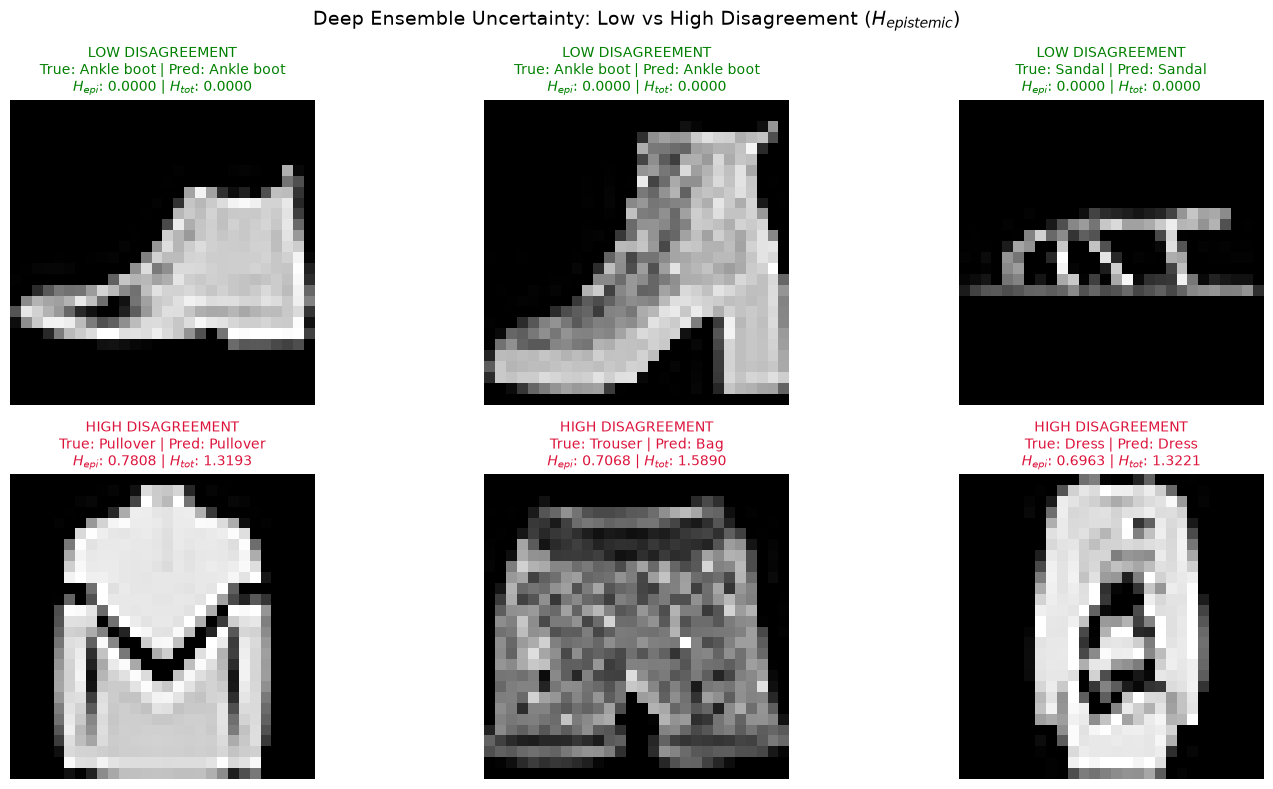

In [36]:
# Sort test set indices by Epistemic Uncertainty (Disagreement)
epistemic_scores = ensemble_res["epistemic_uncertainty"]
sorted_indices = np.argsort(epistemic_scores)

# Top 3 Low Disagreement Examples (Lowest H_epistemic)
low_disagreement_indices = sorted_indices[:3]

# Top 3 High Disagreement Examples (Highest H_epistemic)
high_disagreement_indices = sorted_indices[-3:][::-1]

def unnormalize(tensor_img):
    img = tensor_img.clone().numpy().squeeze()
    img = (img * 0.5) + 0.5
    return np.clip(img, 0, 1)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Row 1: Low Disagreement
for i, idx in enumerate(low_disagreement_indices):
    img, _ = test_dataset[idx]
    true_label = class_names[test_targets_np[idx]]
    ens_pred = class_names[ensemble_res["ensemble_preds"][idx]]
    h_epi = ensemble_res["epistemic_uncertainty"][idx]
    h_tot = ensemble_res["total_entropy"][idx]

    axes[0, i].imshow(unnormalize(img), cmap="gray")
    axes[0, i].set_title(
        f"LOW DISAGREEMENT\nTrue: {true_label} | Pred: {ens_pred}\n"
        rf"$H_{{epi}}$: {h_epi:.4f} | $H_{{tot}}$: {h_tot:.4f}",
        color="green", fontsize=10
    )
    axes[0, i].axis("off")

# Row 2: High Disagreement
for i, idx in enumerate(high_disagreement_indices):
    img, _ = test_dataset[idx]
    true_label = class_names[test_targets_np[idx]]
    ens_pred = class_names[ensemble_res["ensemble_preds"][idx]]
    h_epi = ensemble_res["epistemic_uncertainty"][idx]
    h_tot = ensemble_res["total_entropy"][idx]

    axes[1, i].imshow(unnormalize(img), cmap="gray")
    axes[1, i].set_title(
        f"HIGH DISAGREEMENT\nTrue: {true_label} | Pred: {ens_pred}\n"
        rf"$H_{{epi}}$: {h_epi:.4f} | $H_{{tot}}$: {h_tot:.4f}",
        color="crimson", fontsize=10
    )
    axes[1, i].axis("off")

plt.suptitle(r"Deep Ensemble Uncertainty: Low vs High Disagreement ($H_{epistemic}$)", fontsize=14)
plt.tight_layout()

# Save figure
fig_dir = "figures/SimpleFashionCNN_Ensemble"
os.makedirs(fig_dir, exist_ok=True)
plt.savefig(f"{fig_dir}/ensemble_uncertainty_examples.png", bbox_inches="tight", dpi=300)
plt.show()

### Answering the questions

#### Performance Comparison Table

| Model / Evaluated Entity | Test Accuracy (%) | Total Entropy ($H_{\text{total}}$) | Aleatoric Uncertainty ($H_{\text{aleatoric}}$) | Epistemic Uncertainty ($H_{\text{epistemic}}$) |
| :--- | :---: | :---: | :---: | :---: |
| **Model 1 (Seed 42)** | 91.80% | - | - | - |
| **Model 2 (Seed 101)** | 91.42% | - | - | - |
| **Model 3 (Seed 2024)** | 92.01% | - | - | - |
| **Model 4 (Seed 777)** | 91.37% | - | - | - |
| **Model 5 (Seed 999)** | 91.99% | - | - | - |
| **Average Individual Model** | **91.72%** | - | - | - |
| **Deep Ensemble ($M = 5$)** | **92.90%** | **0.1764** | **0.1389** | **0.0376** |

#### 1. Comparison: Individual Predictions vs. Deep Ensemble

* **Accuracy Gain**: The Deep Ensemble achieved a test accuracy of **92.90%**, outperforming the single best individual model (**Model 3** at 92.01%) and providing a **+1.18% absolute accuracy improvement** over the average individual performance (91.72%).
* **Variance Reduction & Error Correction**: Individual models make uncorrelated errors due to different parameter initializations and batch orderings. Soft voting averages out individual noise and overconfident false positives, yielding a smoother and significantly more reliable probability distribution.

#### 2. What happens when all networks agree?

* **Mathematical Behavior**: When all $M$ models predict nearly identical probability distributions ($p_1 \approx p_2 \approx \dots \approx p_M$), the individual entropy average matches the entropy of the mean distribution:
  $$H_{\text{aleatoric}} \approx H_{\text{total}} \implies H_{\text{epistemic}} = H_{\text{total}} - H_{\text{aleatoric}} \to 0$$
* **Empirical Insight**: As seen in the top row of our visualization (e.g., unambiguous *Ankle boot* and *Sandal* images), $H_{\text{epistemic}} = 0.0000$ and $H_{\text{total}} = 0.0000$. Unanimous consensus indicates high model certainty and zero epistemic disagreement.

#### 3. What happens when networks disagree?

* **Mathematical Behavior**: When individual networks predict different classes or assign conflicting probabilities to candidate classes, the individual entropies $H_{\text{aleatoric}}$ remain relatively low, but the total entropy $H_{\text{total}}$ of the averaged distribution $\bar{p}$ increases sharply. This causes a massive spike in **Epistemic Uncertainty ($H_{\text{epistemic}}$)**.
* **Empirical Insight**: In the bottom row of our visualization (e.g., ambiguous *Pullover* and *Trouser/Bag* images), $H_{\text{epistemic}}$ rises dramatically to **0.6963 – 0.7808** (with $H_{\text{total}} \ge 1.3193$). This disagreement directly flags visually complex, out-of-distribution, or highly ambiguous samples where single models are prone to misclassification.

#### 4. Can the ensemble be uncertain even when the average prediction is relatively confident?

* **Yes, absolutely.**
* **Mechanism**: Consider a scenario with $M=5$ models where 3 models predict Class A with 95% confidence ($p_m(A) = 0.95$), while 2 models predict Class B with 95% confidence ($p_m(B) = 0.95$).
* **Outcome**:
  1. **Average Probability**: $\bar{p}(A) = \frac{3 \times 0.95 + 2 \times 0.05}{5} = \mathbf{0.58}$. The ensemble average selects Class A as the winning prediction with a moderate-to-high majority confidence.
  2. **Aleatoric Uncertainty ($H_{\text{aleatoric}}$)**: Because each individual model was highly confident in its own prediction, $H_{\text{aleatoric}}$ is extremely **low**.
  3. **Epistemic Uncertainty ($H_{\text{epistemic}}$)**: Because the models strongly disagree on *which* class is correct, $H_{\text{epistemic}} = H_{\text{total}} - H_{\text{aleatoric}}$ becomes **very high**.
* **Conclusion**: High epistemic uncertainty reveals that the winning prediction is fragile and rests on a divided consensus, exposing hidden model uncertainty despite a seemingly confident majority vote.